# 00-5　觀看前須知：讀懂 05 量子重力需要的觀念

**給誰看**：讀過 00-1 到 04 的人。
**目標**：讀完再去看 [05 衝突地帶](../05_quantum_gravity/01_where_theories_collide.ipynb)。

05 是整個課程的終點：把 $G$、$c$、$\hbar$ 三個常數**同時打開**。那裡沒有一個完整的理論可以模擬，
所以 05 主要用**估算**：用常數湊出尺度、算數量級、看哪裡會出問題。這本準備需要的工具。

| 章節 | 內容 | 05 對應的地方 |
|---|---|---|
| 0 | 符號對照表 | 全部 |
| 1 | 因次分析：用單位湊出答案 | 普朗克單位 |
| 2 | 數量級與對數 | 從普朗克長度到宇宙 |
| 3 | 溫度與熱輻射 | 霍金輻射 |
| 4 | 熵：數一數有幾種可能 | 黑洞的熵 |
| 5 | 零點能量：量子的東西停不下來 | 真空能量 |
| 6 | 平均值的陷阱 | 半古典重力的問題 |

## 0. 符號對照表

| 符號 | 念法 | 意思 |
|---|---|---|
| $\ell_P$、$t_P$、$m_P$ | 普朗克長度、時間、質量 | 由 $G$、$\hbar$、$c$ 湊出來的自然尺度 |
| $k_B$ | 波茲曼常數 | 溫度和能量的換算：$1.38\times10^{-23}$ J/K |
| $T$ | | 溫度（克耳文 K，0 K = −273.15 °C）。05 裡不再是週期 |
| $S$ | | 熵 |
| $W$ | | 一個系統有多少種可能的微觀狀態 |
| $\ln$ | 自然對數 | $\ln e^x = x$ |
| $\log_{10}$ | 常用對數 | 「10 的幾次方」 |
| $\rho$ | rho | 密度（質量密度或能量密度） |
| $\Lambda$ | lambda 大寫 | 宇宙學常數，暗能量 |
| $\omega$ | omega | 角頻率 $2\pi f$ |
| $\langle A\rangle$ | A 的期望值 | 量子測量很多次的平均（00-2 第 3 章） |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

G, c, hbar, k_B = 6.674e-11, 2.998e8, 1.055e-34, 1.381e-23

## 1. 因次分析：用單位湊出答案

**白話**：物理量都有**單位**（公尺、公斤、秒）。等號兩邊的單位必須一樣。
很多時候，光是要求「單位對得上」，就能猜出答案長什麼樣子。

**例子：單擺的週期**。週期 $T$ 可能和擺長 $L$（公尺）、重力加速度 $g$（公尺/秒²）、擺錘質量 $m$（公斤）有關。
假設 $T = L^a\,g^b\,m^d$，要求單位是「秒」：

- 公尺：$a + b = 0$
- 秒：$-2b = 1$
- 公斤：$d = 0$

解出 $a = 1/2$、$b = -1/2$、$d = 0$，所以 $T \propto \sqrt{L/g}$，**和質量無關**。
（精確答案是 $2\pi\sqrt{L/g}$，因次分析只差一個沒有單位的係數 $2\pi$。）

這個方法 05 會用來回答：**用 $G$、$\hbar$、$c$ 三個常數，能湊出什麼長度？**

In [2]:
# 單位寫成 [公尺, 公斤, 秒] 的次方
units = {
    "L（擺長）": [1, 0, 0],
    "g（重力加速度）": [1, 0, -2],
    "m（質量）": [0, 1, 0],
}
target = [0, 0, 1]      # 想要的單位：秒

A = np.array(list(units.values())).T     # 每一欄是一個物理量的單位
exponents = np.linalg.solve(A, target)
for name, e in zip(units, exponents):
    print(f"{name:<14} 的次方 = {e:+.2f}")
print("→ T ∝ L^(1/2) · g^(−1/2) = √(L/g)")

L（擺長）          的次方 = +0.50
g（重力加速度）       的次方 = -0.50
m（質量）          的次方 = +0.00
→ T ∝ L^(1/2) · g^(−1/2) = √(L/g)


## 2. 數量級與對數

05 會碰到非常大和非常小的數。最好的辦法是只看「**10 的幾次方**」，也就是**數量級**。

- $10^{-35}$ 和 $10^{-34}$ 只差 10 倍，在數量級上是「鄰居」
- 兩個數相乘，次方相加：$10^{20}\times10^{15} = 10^{35}$

把宇宙裡各種長度畫在**對數刻度**上（每一格差 10 倍）：

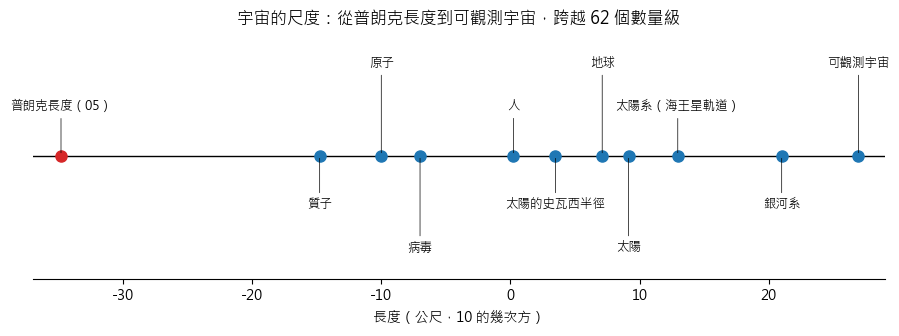

人和質子差 15 個數量級；質子和普朗克長度差 20 個數量級


In [3]:
scales = [
    ("普朗克長度（05）", 1.6e-35),
    ("質子", 1.7e-15),
    ("原子", 1e-10),
    ("病毒", 1e-7),
    ("人", 1.7),
    ("地球", 1.27e7),
    ("太陽的史瓦西半徑", 3e3),
    ("太陽", 1.39e9),
    ("太陽系（海王星軌道）", 9e12),
    ("銀河系", 1e21),
    ("可觀測宇宙", 8.8e26),
]
scales.sort(key=lambda s: s[1])
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.set_xlim(-37, 29)
ax.set_ylim(-1, 1)
ax.axhline(0, color="k", lw=1)
for i, (name, L) in enumerate(scales):
    x = np.log10(L)
    y = [0.4, -0.4, 0.75, -0.75][i % 4]      # 上下交錯兩層，避免標籤重疊
    ax.plot(x, 0, "o", color="C3" if "普朗克" in name else "C0", ms=8)
    ax.annotate(name, (x, 0), (x, y), ha="center", va="center", fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.5))
ax.set_yticks([])
ax.set_xlabel("長度（公尺，10 的幾次方）")
ax.set_title("宇宙的尺度：從普朗克長度到可觀測宇宙，跨越 62 個數量級")
for sp_ in ["left", "right", "top"]:
    ax.spines[sp_].set_visible(False)
plt.show()

print(f"人和質子差 {np.log10(1.7 / 1.7e-15):.0f} 個數量級；質子和普朗克長度差 {np.log10(1.7e-15 / 1.6e-35):.0f} 個數量級")

**最驚人的一點**：質子比普朗克長度大 $10^{20}$ 倍，**比「人比質子大」的倍數（$10^{15}$）還多**。
人類最強的粒子加速器（LHC）能探測到大約 $10^{-19}$ m，離普朗克長度還差 16 個數量級。量子重力的效應離我們非常遙遠。

## 3. 溫度與熱輻射

**白話**：任何有溫度的東西都會發出電磁波（光），叫**熱輻射**。

- 越熱，發出的光越強，而且**顏色越偏向短波長**：電爐從暗紅變橘紅、變黃白
- 人體約 310 K，發出的是看不見的紅外線（熱像儀看得到）
- 理想的熱輻射叫**黑體輻射**，它的光譜形狀只由溫度決定

**維恩定律**：光譜最亮的波長 $\lambda_{\max} = \dfrac{2.898\times10^{-3}\ \text{m·K}}{T}$

（1900 年普朗克為了解釋黑體輻射的光譜，第一次引入了 $h$，這就是量子力學的起點。）

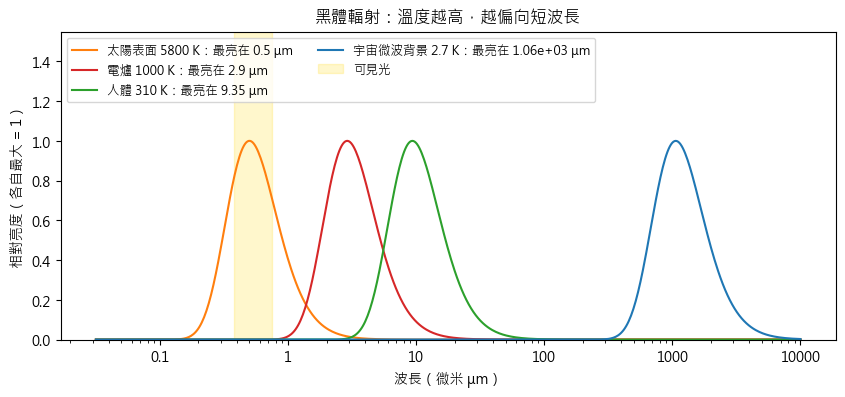

In [4]:
h = 2 * np.pi * hbar

def planck_spectrum(lam, T):
    # 黑體在波長 lam 的輻射強度（普朗克公式）。低溫、短波長時指數會溢位成無限大，強度就是 0，不用警告
    with np.errstate(over="ignore"):
        return 2 * h * c**2 / lam**5 / np.expm1(h * c / (lam * k_B * T))

lam = np.logspace(-7.5, -2, 600)
fig, ax = plt.subplots(figsize=(10, 4))
for name, T, col in [("太陽表面 5800 K", 5800, "C1"), ("電爐 1000 K", 1000, "C3"),
                     ("人體 310 K", 310, "C2"), ("宇宙微波背景 2.7 K", 2.725, "C0")]:
    B = planck_spectrum(lam, T)
    ax.plot(lam * 1e6, B / B.max(), color=col, label=f"{name}：最亮在 {2.898e-3 / T * 1e6:.3g} μm")
ax.axvspan(0.38, 0.75, color="gold", alpha=0.2, label="可見光")
ax.set_xscale("log")
ax.set_xlabel("波長（微米 μm）")
ax.set_ylabel("相對亮度（各自最大 = 1）")
ax.set_title("黑體輻射：溫度越高，越偏向短波長")
ax.set_ylim(0, 1.55)
ax.legend(fontsize=9, loc="upper left", ncol=2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
plt.show()

**05 會看到**：霍金證明黑洞會發出**黑體輻射**，有一個溫度。黑洞越小越熱。
太陽質量的黑洞溫度只有 $6\times10^{-8}$ K，比宇宙背景（2.7 K）冷得多，所以實際上還在吸收比放出多。

## 4. 熵：數一數有幾種可能

**白話**：熵衡量「**有多少種微觀的排列方式，看起來都一樣**」。

**例子**：100 枚硬幣。「巨觀狀態」只看幾枚正面；「微觀狀態」是每一枚各是正是反。

- 全部正面：只有 **1** 種排法
- 50 正 50 反：有 $\binom{100}{50} \approx 10^{29}$ 種排法

**波茲曼公式**（刻在他的墓碑上）：
$$S = k_B \ln W$$
$W$ 是微觀狀態的數目。物理學家常把 $k_B$ 拿掉，用「**位元**」來數：$S = \log_2 W$，就是「要用多少個 0/1 才能記下完整的微觀狀態」。**熵就是資訊。**

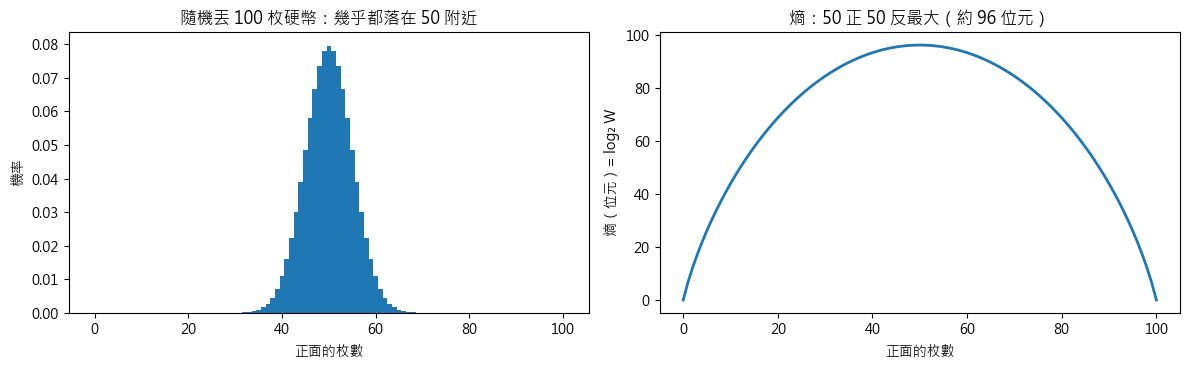

全部正面：W = 1，熵 = 0 位元
50 正 50 反：W = 1.01e+29，熵 = 96.3 位元


In [5]:
n = 100
heads = np.arange(n + 1)
W = np.array([comb(n, k) for k in heads], dtype=float)
bits = np.log2(W)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(heads, W / W.sum(), width=1)
axes[0].set_xlabel("正面的枚數")
axes[0].set_ylabel("機率")
axes[0].set_title("隨機丟 100 枚硬幣：幾乎都落在 50 附近")
axes[1].plot(heads, bits, lw=2)
axes[1].set_xlabel("正面的枚數")
axes[1].set_ylabel("熵（位元）= log₂ W")
axes[1].set_title("熵：50 正 50 反最大（約 96 位元）")
plt.tight_layout()
plt.show()

print(f"全部正面：W = 1，熵 = 0 位元")
print(f"50 正 50 反：W = {W[50]:.2e}，熵 = {bits[50]:.1f} 位元")

**熱力學第二定律**：一個孤立系統的熵**不會減少**。原因很單純：熵大的狀態，排法多得多，隨機變化幾乎一定往那裡跑。

**05 的伏筆**：1972 年，貝肯斯坦發現**黑洞也必須有熵**，否則把一杯熱茶丟進黑洞，熵就消失了，違反第二定律。
而且黑洞的熵正比於**視界的面積**（不是體積），大得驚人。熵代表有很多種微觀狀態，可是古典廣義相對論的黑洞只由質量、電荷、自轉三個數決定。
**那些微觀狀態到底是什麼？** 這是量子重力最重要的線索之一。

## 5. 零點能量：量子的東西停不下來

**白話**：一顆彈簧上的球（**諧振子**），古典上可以完全靜止在中心，能量是 0。

量子力學不允許：「完全靜止在中心」代表位置確定（$\Delta x = 0$）、動量也確定（$\Delta p = 0$），違反不確定性原理（02-1）。
所以量子諧振子能量最低的狀態，還是有一點點能量，叫**零點能量**：

$$E_0 = \frac12\hbar\omega$$

**為什麼這和真空有關？** 量子場論說，真空中的電磁場（和其他每一種場）可以拆成**無數個不同頻率的振子**（00-2 第 5 章的傅立葉拆解）。
每個振子都有自己的 $\frac12\hbar\omega$。全部加起來……就是 05 要算的「真空能量」。

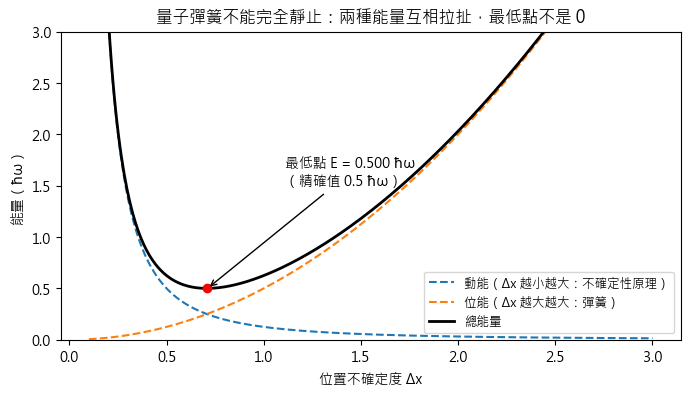

In [6]:
# 用不確定性原理估計諧振子的最低能量：E(Δx) = 動能 + 位能，其中 Δp 至少是 ħ/(2Δx)
m_osc, omega = 1.0, 1.0           # 自然單位（ħ = 1）
dx = np.linspace(0.1, 3, 400)
E_kin = (1 / (2 * dx)) ** 2 / (2 * m_osc)
E_pot = 0.5 * m_osc * omega**2 * dx**2
E_tot = E_kin + E_pot

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(dx, E_kin, "--", label="動能（Δx 越小越大：不確定性原理）")
ax.plot(dx, E_pot, "--", label="位能（Δx 越大越大：彈簧）")
ax.plot(dx, E_tot, "k", lw=2, label="總能量")
i = np.argmin(E_tot)
ax.plot(dx[i], E_tot[i], "ro")
ax.annotate(f"最低點 E = {E_tot[i]:.3f} ħω\n（精確值 0.5 ħω）", (dx[i], E_tot[i]), (dx[i] + 0.4, 1.5),
            arrowprops=dict(arrowstyle="->"))
ax.set_ylim(0, 3)
ax.set_xlabel("位置不確定度 Δx")
ax.set_ylabel("能量（ħω）")
ax.set_title("量子彈簧不能完全靜止：兩種能量互相拉扯，最低點不是 0")
ax.legend(fontsize=9)
plt.show()

動能和位能互相拉扯：擠得太緊動能變大，放得太鬆位能變大，最低點剛好是 $\frac12\hbar\omega$。
**真空不是「什麼都沒有」，而是每一個振子都在最低能量狀態「微微顫動」。** 這叫**真空漲落**，已經在實驗中證實（例如卡西米爾效應：兩片很近的金屬板會被真空漲落推在一起）。

## 6. 平均值的陷阱

00-2 說過：量子力學只能預測很多次測量的**平均**（期望值 $\langle A\rangle$）。

**陷阱**：平均值可能是一個**從來不會發生**的值。

**例子**：一顆球處在「50% 在左邊（$x = -1$）、50% 在右邊（$x = +1$）」的疊加態（02-1 實驗 3 的貓態）。

- 每次測量，球**不是在 −1 就是在 +1**
- 但平均位置 $\langle x\rangle = 0$，那是**球從來不會出現的地方**

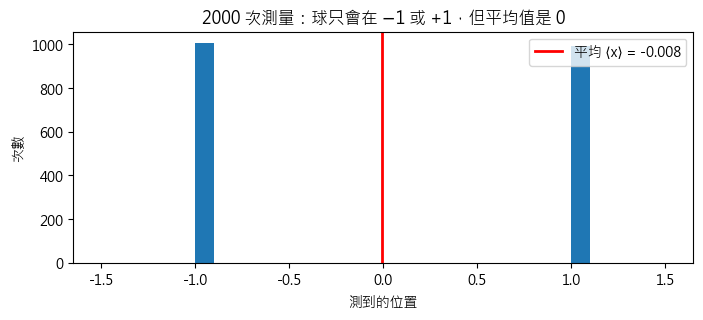

In [7]:
rng = np.random.default_rng(2)
measurements = rng.choice([-1, 1], size=2000)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(measurements, bins=np.linspace(-1.5, 1.5, 31), color="C0")
ax.axvline(measurements.mean(), color="r", lw=2, label=f"平均 ⟨x⟩ = {measurements.mean():.3f}")
ax.set_xlabel("測到的位置")
ax.set_ylabel("次數")
ax.set_title("2000 次測量：球只會在 −1 或 +1，但平均值是 0")
ax.legend()
plt.show()

**05 的伏筆**：「半古典重力」把愛因斯坦方程式右邊的物質換成**量子期望值** $\langle T_{\mu\nu}\rangle$。
如果一顆很重的球處在「左邊和右邊」的疊加態，半古典重力會說：**引力來自中間**，那個球從來不在的地方。
05 會模擬這件事，並說明 1981 年的實驗怎麼排除了它。

## 準備好了：去讀 05

| 你在 05 看到 | 這本的哪裡 |
|---|---|
| 普朗克長度、時間、質量 | 第 1 章（因次分析） |
| $10^{-35}$、$10^{120}$ 這種數字 | 第 2 章 |
| 霍金溫度、黑體輻射 | 第 3 章 |
| 黑洞的熵、面積定律、位元 | 第 4 章 |
| 真空能量、零點能量 | 第 5 章 |
| 半古典重力、$\langle T_{\mu\nu}\rangle$ | 第 6 章 |

## 小練習

1. 第 1 章：用因次分析猜，一個質量 $M$ 的星球表面的逃逸速度怎麼和 $G$、$M$、$R$ 有關？和 00-4 第 5 章的公式比對。
2. 第 3 章：一顆溫度 3000 K 的紅矮星，最亮的波長在哪裡？是什麼顏色？
3. 第 4 章：1000 枚硬幣 500 正 500 反，熵大約是多少位元？